In [31]:
import os
os.environ.pop("PYTHONPATH", None)

import sys
sys.path = [p for p in sys.path if "/opt/software-current/" not in p]

import regex
print("regex:", regex.__file__)

regex: /mnt/home/linpaul1/Documents/SPROUT/.venv/lib/python3.13/site-packages/regex/__init__.py


In [32]:
import pandas as pd
import numpy as np

df = pd.read_parquet("../../data/unsplash/clip_train.parquet")
collections_df = pd.read_csv("../../data/unsplash/collections.tsv000", sep="\t")
collections_df["collection_id"] = collections_df["collection_id"].astype(str)

df["image_path"] = [f"../../data/unsplash/{i}" for i in df["image_path"]]

In [33]:
HELDOUT_TEST = True

inject_df = pd.read_csv("../../data/small/metadata.csv")
inj = inject_df.iloc[:10].reset_index(drop=True)

new_rows = pd.DataFrame({
    "photo_id": [f"laptop_twee_{i}" for i in range(len(inj))],
    "image_path": [f"../../data/small/{p}" for p in inj["image_path"]],
    "caption": inj["caption"].astype(str),
})
df = pd.concat([df, new_rows], ignore_index=True)

all_ids = new_rows["photo_id"].tolist()
inboard_ids = all_ids[:5] if HELDOUT_TEST else all_ids
heldout_ids = all_ids[5:] if HELDOUT_TEST else []

collections_df = pd.concat([collections_df, pd.DataFrame({
    "photo_id": inboard_ids,
    "collection_id": "laptop_twee",
    "collection_title": "laptop twee",
})], ignore_index=True)

print(len(df), "photos |", len(inboard_ids), "in board |", len(heldout_ids), "held out")

25007 photos | 5 in board | 5 held out


In [34]:
import torch
import torch.nn.functional as F
from transformers import AutoModel, AutoProcessor
from sentence_transformers import SentenceTransformer
from PIL import Image

MODEL_NAME = "google/siglip2-base-patch16-224"
device = "cuda" if torch.cuda.is_available() else "cpu"

embed_model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()
embed_processor = AutoProcessor.from_pretrained(MODEL_NAME)
st = SentenceTransformer("all-MiniLM-L6-v2", device=device)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 16764.85it/s]


In [35]:
def embed_images_batch(image_paths, batch_size=1024):
    embeddings = []
    for start in range(0, len(image_paths), batch_size):
        images = []
        for path in image_paths[start:start + batch_size]:
            with Image.open(path) as img:
                images.append(img.convert("RGB"))
        inputs = embed_processor(images=images, return_tensors="pt").to(device)
        with torch.inference_mode():
            out = embed_model.get_image_features(**inputs)
        out = getattr(out, "pooler_output", out)
        embeddings.append(F.normalize(out.float(), dim=-1))
    return torch.cat(embeddings)


def embed_text_batch(texts, batch_size=1024):  # SigLIP text -> matches images
    embeddings = []
    for start in range(0, len(texts), batch_size):
        inputs = embed_processor(text=texts[start:start + batch_size], padding="max_length",
                                 max_length=64, truncation=True, return_tensors="pt").to(device)
        with torch.inference_mode():
            out = embed_model.get_text_features(**inputs)
        out = getattr(out, "pooler_output", out)
        embeddings.append(F.normalize(out.float(), dim=-1))
    return torch.cat(embeddings)


def embed_text_batch_st(texts, batch_size=1024):  # sentence-transformer -> matches text
    return st.encode(texts, batch_size=batch_size, convert_to_tensor=True,
                     normalize_embeddings=True, show_progress_bar=True).float()

In [17]:
X = embed_images_batch(df["image_path"].tolist())
print(X.shape)

torch.Size([25007, 768])


In [ ]:
photo_to_idx = {p: i for i, p in enumerate(df["photo_id"])}
unique_collections = (collections_df[["collection_id", "collection_title"]]
                      .drop_duplicates("collection_id").reset_index(drop=True))
collection_to_idx = {c: i for i, c in enumerate(unique_collections["collection_id"])}

titles = unique_collections["collection_title"].fillna("").astype(str).str.lower().tolist()
B = embed_text_batch_st(titles)

pc = collections_df[collections_df["photo_id"].isin(photo_to_idx)].drop_duplicates(["photo_id", "collection_id"])
pc_photo = torch.tensor(pc["photo_id"].map(photo_to_idx).values, device=device)
pc_board = torch.tensor(pc["collection_id"].map(collection_to_idx).values, device=device)
board_size = torch.bincount(pc_board, minlength=len(titles)).float()

print(len(titles), "boards,", len(pc), "photo-board links")

Batches: 100%|██████████| 546/546 [00:22<00:00, 24.00it/s]


558147 boards, 2204773 photo-board links


In [47]:
def search(query, match_threshold=0.75, match_softness=0.05, max_seeds=200, top_matches=3):
    # 1. the query text is matched against BOARD TITLES only (soft match);
    #    small boards count more than huge generic ones
    query_text_embedding = embed_text_batch_st([query.lower()])[0]
    board_title_similarity = B @ query_text_embedding
    board_relevance = torch.sigmoid((board_title_similarity - match_threshold) / match_softness)
    board_weight = board_relevance / torch.log(2 + board_size)

    # 2. each photo's seed score = sum of the weights of ALL boards it belongs to
    seed_score = torch.zeros(len(X), device=device)
    seed_score.index_add_(0, pc_photo, board_weight[pc_board])
    seed_score = seed_score / seed_score.max().clamp(min=1e-8)

    # 3. pick the seed images: photos from matching boards (strongest first, capped)
    seed_strength, seed_indices = seed_score.topk(max_seeds)
    keep = seed_strength > 0.1
    seed_strength, seed_indices = seed_strength[keep], seed_indices[keep]

    # 4. visual score: how similar each image is to the seed images
    #    (average of its best few seed matches, so it can match one sub-style of the trend)
    if len(seed_indices) > 0:
        similarity_to_seeds = X_learned[seed_indices] @ X_learned.T          # (num_seeds, num_photos)
        similarity_to_seeds = similarity_to_seeds * seed_strength[:, None]
        k = min(top_matches, len(seed_indices))
        visual_score = similarity_to_seeds.topk(k, dim=0).values.mean(dim=0)
    else:
        visual_score = torch.zeros(len(X), device=device)

    # 5. direct SigLIP text->image score as a tiebreaker,
    #    turned down when the query strongly matches a board
    query_image_embedding = embed_text_batch([query])[0]
    siglip_score = X @ query_image_embedding
    siglip_weight = 1 - 0.8 * board_relevance.max()

    def standardize(values):
        return (values - values.mean()) / (values.std() + 1e-6)

    final_score = standardize(visual_score) + siglip_weight * standardize(siglip_score)

    top_boards = unique_collections.assign(relevance=board_relevance.cpu().numpy())
    print(top_boards.nlargest(5, "relevance")[["collection_title", "relevance"]])
    print(len(seed_indices), "seed images")

    return df.assign(
        score=final_score.cpu().numpy(),
        seed=seed_score.cpu().numpy(),
        s_visual=visual_score.cpu().numpy(),
        s_siglip=siglip_score.cpu().numpy(),
    ).sort_values("score", ascending=False)

In [43]:
import torch.nn as nn

# training data: photo-board links, EXCLUDING the laptop twee board (no leakage into the test)
MIN_BOARD_SIZE, MAX_BOARD_SIZE = 20, 500     # skip tiny boards and giant generic ones
train_links = pc[pc["collection_id"] != "laptop_twee"]
board_sizes = train_links["collection_id"].value_counts()
usable_boards = board_sizes[(board_sizes >= MIN_BOARD_SIZE) & (board_sizes <= MAX_BOARD_SIZE)].index
train_links = train_links[train_links["collection_id"].isin(usable_boards)]

photos_per_board = [
    torch.tensor(group["photo_id"].map(photo_to_idx).values, device=device)
    for _, group in train_links.groupby("collection_id")
]
print(len(photos_per_board), "training boards")


def supervised_contrastive_loss(embeddings, labels, temperature=0.1):
    similarity = embeddings @ embeddings.T / temperature
    is_self = torch.eye(len(embeddings), dtype=torch.bool, device=embeddings.device)
    similarity = similarity.masked_fill(is_self, -1e9)
    log_prob = similarity - torch.logsumexp(similarity, dim=1, keepdim=True)
    is_positive = (labels[:, None] == labels[None, :]) & ~is_self
    return -((log_prob * is_positive).sum(1) / is_positive.sum(1).clamp(min=1)).mean()


style_projection = nn.Sequential(
    nn.Linear(X.shape[1], 512), nn.ReLU(), nn.Linear(512, 128)
).to(device)
optimizer = torch.optim.Adam(style_projection.parameters(), lr=1e-3)

BOARDS_PER_BATCH, PHOTOS_PER_BOARD, NUM_STEPS = 32, 8, 2000
for step in range(NUM_STEPS):
    chosen_boards = torch.randint(len(photos_per_board), (BOARDS_PER_BATCH,))
    batch_indices, batch_labels = [], []
    for label, board in enumerate(chosen_boards.tolist()):
        members = photos_per_board[board]
        picks = members[torch.randint(len(members), (PHOTOS_PER_BOARD,), device=device)]
        batch_indices.append(picks)
        batch_labels.append(torch.full((PHOTOS_PER_BOARD,), label, device=device))
    batch_indices, batch_labels = torch.cat(batch_indices), torch.cat(batch_labels)

    projected = F.normalize(style_projection(X[batch_indices]), dim=-1)
    loss = supervised_contrastive_loss(projected, batch_labels)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if step % 200 == 0:
        print(step, round(loss.item(), 4))

14127 training boards
0 5.4784
200 4.8438
400 4.946
600 5.0096
800 5.23
1000 4.9276
1200 5.0
1400 5.0954
1600 4.915
1800 5.1401


In [44]:
with torch.no_grad():
    X_learned = F.normalize(style_projection(X), dim=-1)

Batches: 100%|██████████| 1/1 [00:00<00:00, 36.42it/s]


       collection_title  relevance
558146      laptop twee   0.993307
4913             Laptop   0.146669
5714             Laptop   0.146669
56098           laptop    0.146669
64313            Laptop   0.146669
149 seed images


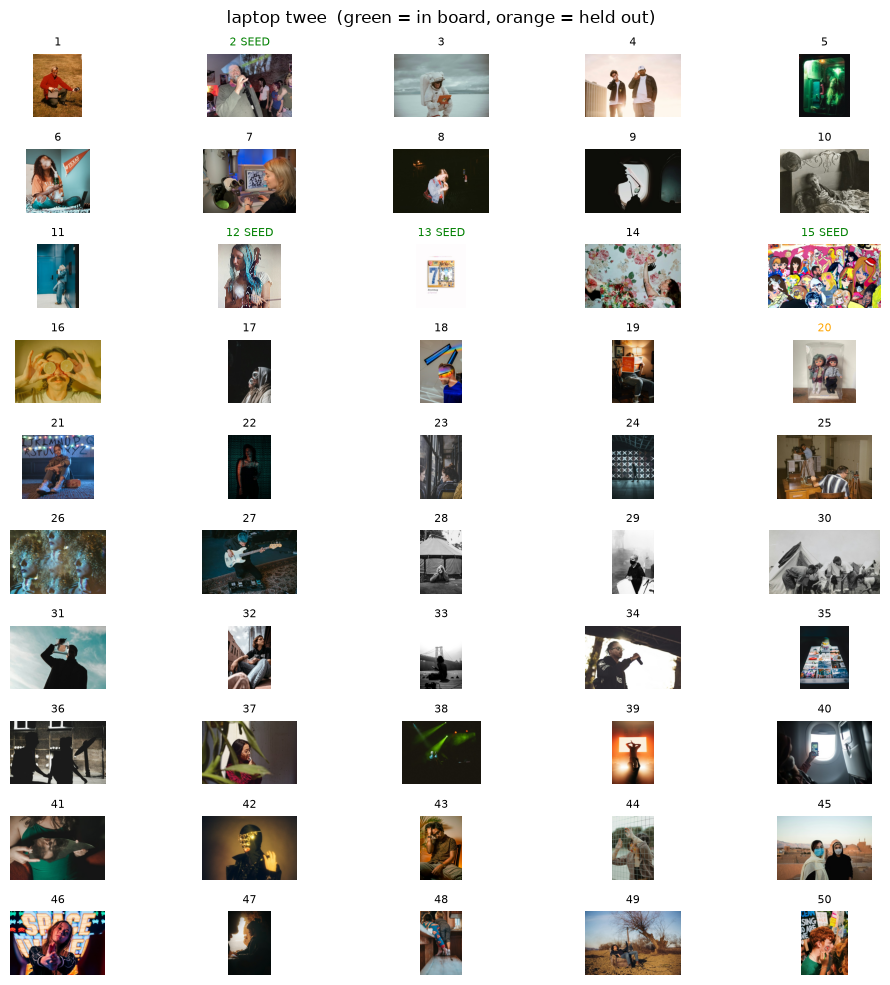

Batches: 100%|██████████| 1/1 [00:00<00:00, 34.81it/s]


       collection_title  relevance
20687               Car   0.993307
43375               car   0.993307
46598               car   0.993307
74904               Car   0.993307
119638              Car   0.993307
18 seed images


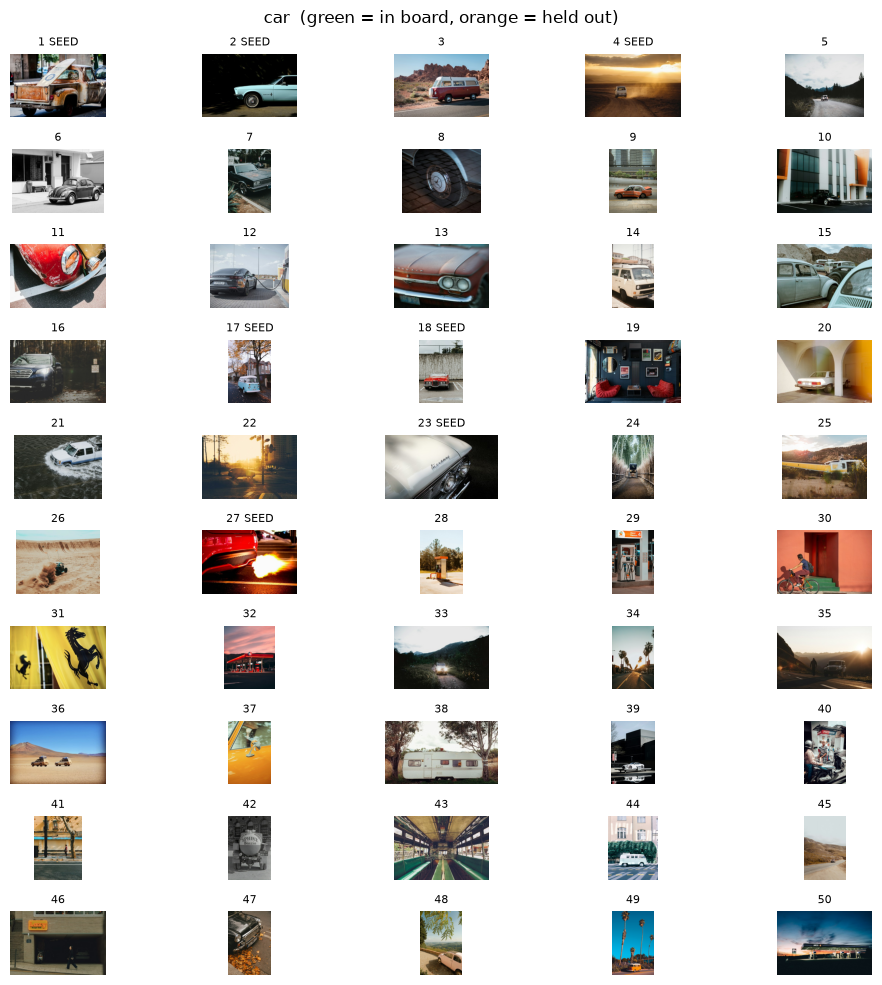

In [49]:
import matplotlib.pyplot as plt

for query in ["laptop twee", "car"]:
    res = search(query)
    fig, axes = plt.subplots(10, 5, figsize=(10, 10))
    for i, ax in enumerate(axes.flat):
        row = res.iloc[i]
        ax.imshow(Image.open(row["image_path"]))
        ax.axis("off")
        ax.set_title(f"{i + 1}{' SEED' if row['seed'] > 0.1 else ''}", fontsize=8,
                     color="orange" if row["photo_id"] in heldout_ids
                     else "green" if row["photo_id"] in inboard_ids else "black")
    fig.suptitle(f"{query}  (green = in board, orange = held out)")
    plt.tight_layout()
    plt.show()